# Oral cancer detection with EfficientNetB0

Colab-ready grouped-split training workflow for Normal vs OSCC. Run in a GPU runtime to produce trained checkpoints and fresh metrics. Patient identifiers have not been verified, so this workflow does not claim patient-level independence. Research use only; outputs are not a diagnosis.


In [1]:
!pip -q install kagglehub ImageHash scikit-learn seaborn


In [2]:
import os, re, time, json, hashlib, random
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES=False
import tensorflow as tf
SEED=42; random.seed(SEED); np.random.seed(SEED)
print('TensorFlow',tf.__version__,'devices',tf.config.list_physical_devices())
try:
 for gpu in tf.config.list_physical_devices('GPU'): tf.config.experimental.set_memory_growth(gpu,True)
except RuntimeError as e: print(e)


TensorFlow 2.21.0 devices [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Dataset download and audit

The source notebook recorded 4,946 images in train and 126 in test. Re-inventory the current Kaggle download. Supplied train/test folders are pooled before group splitting so detected relatives cannot cross partitions; original folder is retained for audit.


In [3]:
import kagglehub
root=Path(kagglehub.dataset_download('ashenafifasilkebede/dataset'))
rows=[]; bad=[]
for split in ['train','test']:
 for cls in ['Normal','OSCC']:
  folder=root/split/cls
  if not folder.exists(): continue
  for p in folder.rglob('*'):
   if not p.is_file(): continue
   try:
    with Image.open(p) as im: im.verify()
    with Image.open(p) as im: w,h=im.size; mode=im.mode
    rows.append(dict(path=str(p),filename=p.name,source_split=split,label=cls,width=w,height=h,mode=mode,sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
   except Exception as e: bad.append((str(p),str(e)))
df=pd.DataFrame(rows)
print('Images',len(df),'unreadable',len(bad)); print(df.groupby(['source_split','label']).size().unstack(fill_value=0)); print(df[['width','height']].describe()); print('Modes',df['mode'].value_counts().to_dict()); print('aug_ names',df.filename.str.lower().str.startswith('aug_').sum())



100%|██████████| 2.93G/2.93G [02:53<00:00, 18.1MB/s]

Extracting files...


Images 5072 unreadable 0
label         Normal  OSCC
source_split              
test              31    95
train           2435  2511
             width       height
count  5072.000000  5072.000000
mean    599.217666   531.381703
std     717.706688   590.458531
min     224.000000   224.000000
25%     224.000000   224.000000
50%     224.000000   224.000000
75%     224.000000   224.000000
max    2048.000000  2048.000000
Modes {'RGB': 5072}
aug_ names 3968


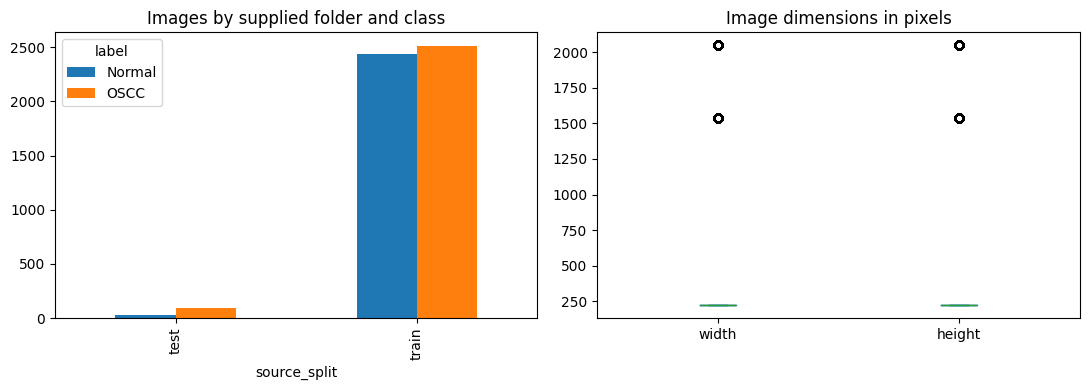

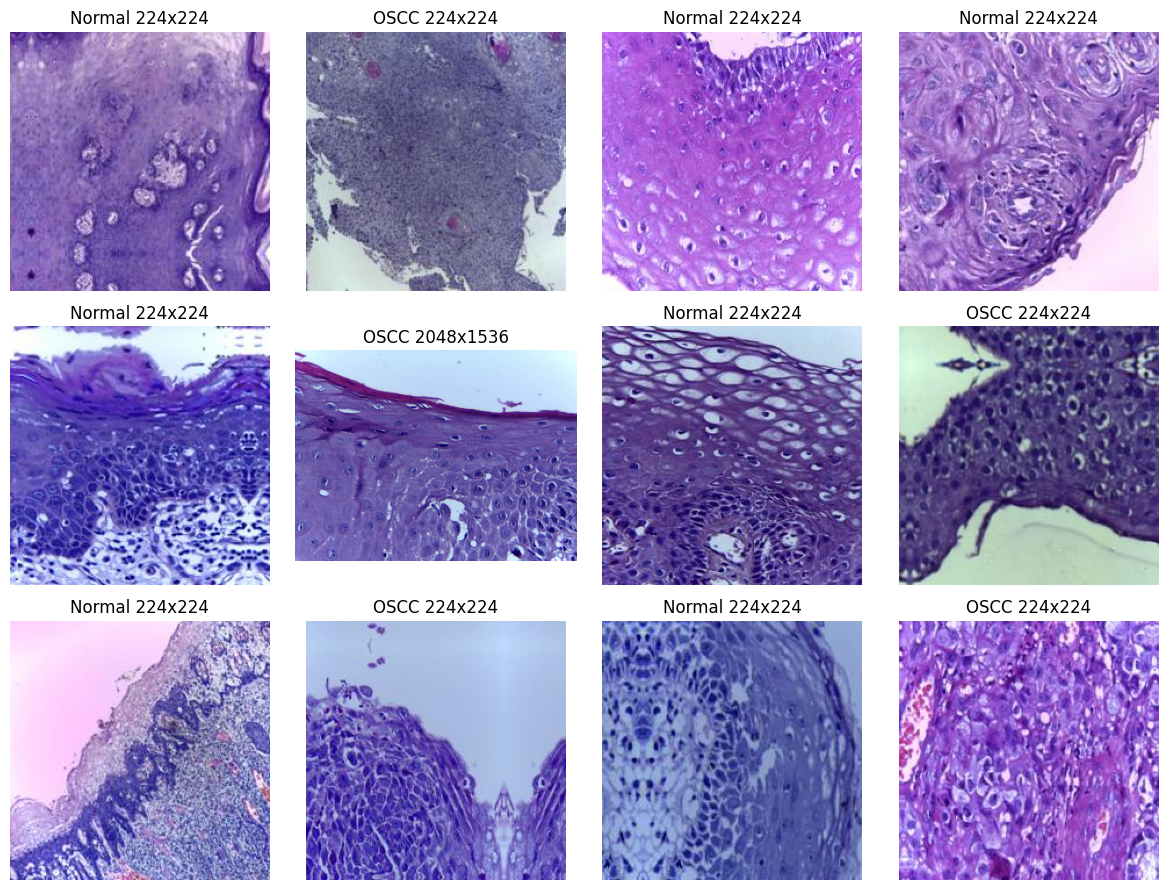

In [4]:
os.makedirs('outputs',exist_ok=True)
fig,ax=plt.subplots(1,2,figsize=(11,4))
df.groupby(['source_split','label']).size().unstack(fill_value=0).plot.bar(ax=ax[0],title='Images by supplied folder and class')
df[['width','height']].plot(kind='box',ax=ax[1],title='Image dimensions in pixels')
fig.tight_layout(); fig.savefig('outputs/dataset_audit.png',dpi=160); plt.show()
sample=df.sample(min(12,len(df)),random_state=SEED); fig,axs=plt.subplots(3,4,figsize=(12,9))
for ax,(_,row) in zip(axs.flat,sample.iterrows()):
 with Image.open(row.path) as im: ax.imshow(im.convert('RGB'))
 ax.set_title(f"{row.label} {row.width}x{row.height}"); ax.axis('off')
fig.tight_layout(); fig.savefig('outputs/image_samples.png',dpi=160); plt.show()


## Similarity groups and leakage-aware split

Groups combine normalized filename stems, exact SHA-256 duplicates, and perceptual hashes within Hamming distance 4. This reduces image-level leakage risk but cannot identify patients. Review group sizes and image examples.


In [5]:
import imagehash
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import GroupShuffleSplit
parent=list(range(len(df)))
def find(a):
 while parent[a]!=a: parent[a]=parent[parent[a]]; a=parent[a]
 return a
def union(a,b):
 a,b=find(a),find(b)
 if a!=b: parent[b]=a
def stem(s):
 s=Path(s).stem.lower(); s=re.sub(r"^(aug|augmented)[_-]+","",s); return s
for _,ix in df.groupby(df.filename.map(stem)).groups.items():
 ix=list(ix)
 for j in ix[1:]: union(ix[0],j)
for _,ix in df.groupby('sha256').groups.items():
 ix=list(ix)
 for j in ix[1:]: union(ix[0],j)
H=[]
for p in df.path:
 with Image.open(p) as im: H.append(np.asarray(imagehash.phash(im.convert('RGB')).hash).reshape(-1))
H=np.stack(H).astype(bool); nn=NearestNeighbors(radius=4/64,metric='hamming',algorithm='brute',n_jobs=-1).fit(H)
for i,ns in enumerate(nn.radius_neighbors(H,return_distance=False)):
 for j in ns:
  if j>i: union(i,int(j))
df['group_id']=[find(i) for i in range(len(df))]
print('images',len(df),'groups',df.group_id.nunique(),'largest',df.groupby('group_id').size().max()); display(df.groupby('group_id').size().describe())
gss=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=42); a,b=next(gss.split(df,df.label,groups=df.group_id)); remain=df.iloc[a].copy(); test_df=df.iloc[b].copy()
gss=GroupShuffleSplit(n_splits=1,test_size=.17647,random_state=43); a,b=next(gss.split(remain,remain.label,groups=remain.group_id)); train_df=remain.iloc[a].copy(); val_df=remain.iloc[b].copy()
assert not(set(train_df.group_id)&set(val_df.group_id) or set(train_df.group_id)&set(test_df.group_id) or set(val_df.group_id)&set(test_df.group_id))
for n,d in [('train',train_df),('validation',val_df),('test',test_df)]: print(n,len(d),d.label.value_counts().to_dict(),'groups',d.group_id.nunique())





images 5072 groups 4607 largest 5


,0
count,4607.000000
mean,1.100933
std,0.360340
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,5.000000


train 3549 {'OSCC': 1838, 'Normal': 1711} groups 3224
validation 755 {'OSCC': 385, 'Normal': 370} groups 691
test 768 {'Normal': 385, 'OSCC': 383} groups 692


## EfficientNetB0: frozen head then fine-tune

RGB inputs are resized to 224x224 and remain 0–255, matching Keras EfficientNet preprocessing. Augmentation is training-only and modest.


In [6]:
IMG=(224,224); BATCH=32; AUTOTUNE=tf.data.AUTOTUNE
classes={'Normal':0,'OSCC':1}
def dataset(frame,training=False):
 ds=tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(),frame.label.map(classes).to_numpy(np.int32)))
 if training: ds=ds.shuffle(len(frame),seed=42)
 def load(p,y):
  x=tf.io.decode_image(tf.io.read_file(p),channels=3,expand_animations=False); x.set_shape([None,None,3]); return tf.image.resize(x,IMG,antialias=True),y
 return ds.map(load,num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
train_ds=dataset(train_df,True); val_ds=dataset(val_df); test_ds=dataset(test_df)
aug=tf.keras.Sequential([tf.keras.layers.RandomFlip('horizontal_and_vertical'),tf.keras.layers.RandomRotation(.04),tf.keras.layers.RandomZoom(.08),tf.keras.layers.RandomContrast(.08)])
base=tf.keras.applications.EfficientNetB0(include_top=False,weights='imagenet',input_shape=(*IMG,3)); base.trainable=False
inp=tf.keras.Input((*IMG,3)); x=aug(inp); x=tf.keras.applications.efficientnet.preprocess_input(x); x=base(x,training=False); x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Dropout(.35)(x); x=tf.keras.layers.Dense(128,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x); x=tf.keras.layers.Dropout(.25)(x); out=tf.keras.layers.Dense(1,activation='sigmoid')(x); model=tf.keras.Model(inp,out)
model.compile(tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy',metrics=['accuracy',tf.keras.metrics.AUC(name='roc_auc'),tf.keras.metrics.AUC(name='pr_auc',curve='PR')])
os.makedirs('outputs',exist_ok=True)
callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.25,patience=2,min_lr=1e-7),tf.keras.callbacks.ModelCheckpoint('outputs/baseline_efficientnetb0.keras',monitor='val_loss',save_best_only=True)]
from sklearn.metrics import accuracy_score,recall_score,f1_score,roc_auc_score,average_precision_score

def val_summary(model):
 p=model.predict(val_ds,verbose=0).ravel(); y=val_df.label.map(classes).to_numpy(); pred=p>=.5
 tn,fp,fn,tp=__import__('sklearn.metrics').metrics.confusion_matrix(y,pred,labels=[0,1]).ravel()
 return dict(validation_accuracy=accuracy_score(y,pred),validation_sensitivity=recall_score(y,pred,zero_division=0),validation_specificity=tn/(tn+fp),validation_f1=f1_score(y,pred,zero_division=0),validation_roc_auc=roc_auc_score(y,p),validation_pr_auc=average_precision_score(y,p))
t=time.time(); h1=model.fit(train_ds,validation_data=val_ds,epochs=20,callbacks=callbacks); head_seconds=time.time()-t
baseline_val=val_summary(model)
base.trainable=True
for layer in base.layers[:-40]: layer.trainable=False
for layer in base.layers:
 if isinstance(layer,tf.keras.layers.BatchNormalization): layer.trainable=False
model.compile(tf.keras.optimizers.Adam(1e-5),loss='binary_crossentropy',metrics=['accuracy',tf.keras.metrics.AUC(name='roc_auc'),tf.keras.metrics.AUC(name='pr_auc',curve='PR')])
callbacks2=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=.25,patience=2,min_lr=1e-7),tf.keras.callbacks.ModelCheckpoint('outputs/best_efficientnetb0.keras',monitor='val_loss',save_best_only=True)]
t=time.time(); h2=model.fit(train_ds,validation_data=val_ds,epochs=15,callbacks=callbacks2); ft_seconds=time.time()-t
model=tf.keras.models.load_model('outputs/best_efficientnetb0.keras')



16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 77s 531ms/step - accuracy: 0.7557 - loss: 0.5665 - pr_auc: 0.8590 - roc_auc: 0.8408 - val_accuracy: 0.8609 - val_loss: 0.3785 - val_pr_auc: 0.9467 - val_roc_auc: 0.9401 - learning_rate: 0.0010
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 54s 483ms/step - accuracy: 0.8278 - loss: 0.4131 - pr_auc: 0.9218 - roc_auc: 0.9135 - val_accuracy: 0.8967 - val_loss: 0.3086 - val_pr_auc: 0.9647 - val_roc_auc: 0.9608 - learning_rate: 0.0010
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 53s 483ms/step - accuracy: 0.8580 - loss: 0.3523 - pr_auc: 0.9412 - roc_auc: 0.9358 - val_accuracy: 0.8993 - val_loss: 0.2685 - val_pr_auc: 0.9718 - val_roc_auc: 0.9682 - learning_rate: 0.0010
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 54s 483ms/step - accuracy: 0.8735 - loss: 0.3175 - pr_auc: 0.9527 - roc_auc: 0.9484 - val_accuracy: 0.9099 - val_loss: 0.2463 - val_pr_auc: 0.9745 - val_roc_auc: 0.9712 - learning_rate: 0.0010
Epoch 5/20
111/11

## Validation threshold and grouped test metrics

Select threshold using validation only, targeting sensitivity >= 0.90; maximize specificity among qualifying thresholds. If infeasible, use the highest-sensitivity threshold. Evaluate test once.


{
  "accuracy": 0.9479166666666666,
  "precision": 1.0,
  "sensitivity": 0.8955613577023499,
  "specificity": 1.0,
  "f1": 0.9449035812672176,
  "roc_auc": 0.9933166050659523,
  "pr_auc": 0.9941759694140895,
  "false_negative_rate": 0.10443864229765012,
  "false_positive_rate": 0.0,
  "threshold": 0.8502655625343323
}
              precision    recall  f1-score   support

      Normal       0.91      1.00      0.95       385
        OSCC       1.00      0.90      0.94       383

    accuracy                           0.95       768
   macro avg       0.95      0.95      0.95       768
weighted avg       0.95      0.95      0.95       768



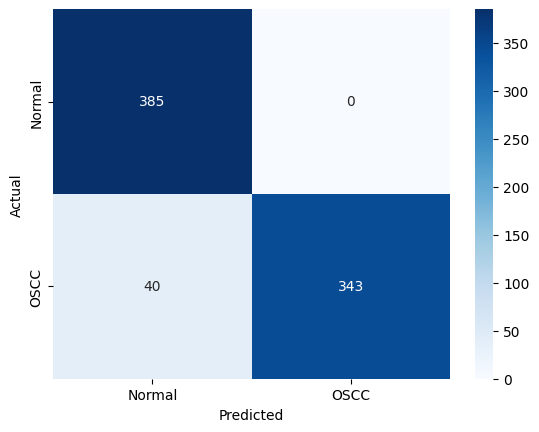

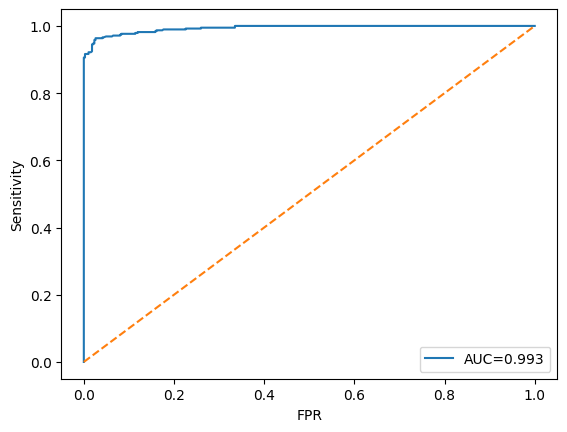

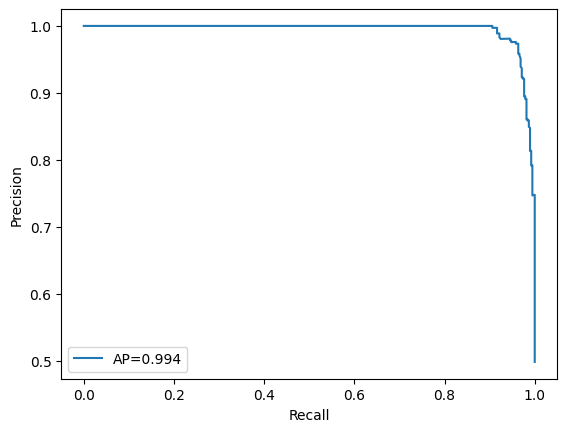

In [7]:
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve
def probs(frame): return model.predict(dataset(frame),verbose=0).ravel(),frame.label.map(classes).to_numpy()
pv,yv=probs(val_df); candidates=[]
for t in np.unique(np.r_[0,pv,1]):
 pred=pv>=t; sens=recall_score(yv,pred,zero_division=0); spec=recall_score(1-yv,1-pred,zero_division=0); candidates.append((t,sens,spec))
eligible=[z for z in candidates if z[1]>=.90]; threshold=max(eligible,key=lambda z:z[2])[0] if eligible else max(candidates,key=lambda z:z[1])[0]
pt,yt=probs(test_df); yp=pt>=threshold; cm=confusion_matrix(yt,yp,labels=[0,1]); tn,fp,fn,tp=cm.ravel()
metrics=dict(accuracy=accuracy_score(yt,yp),precision=precision_score(yt,yp,zero_division=0),sensitivity=recall_score(yt,yp,zero_division=0),specificity=tn/(tn+fp),f1=f1_score(yt,yp,zero_division=0),roc_auc=roc_auc_score(yt,pt),pr_auc=average_precision_score(yt,pt),false_negative_rate=fn/(fn+tp),false_positive_rate=fp/(fp+tn),threshold=float(threshold))
print(json.dumps(metrics,indent=2)); report=classification_report(yt,yp,target_names=['Normal','OSCC'],zero_division=0); print(report)
Path('outputs/classification_report.txt').write_text(report+'\n'+json.dumps(metrics,indent=2)); Path('outputs/test_metrics.json').write_text(json.dumps(metrics,indent=2))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Normal','OSCC'],yticklabels=['Normal','OSCC']); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.savefig('outputs/confusion_matrix.png',dpi=160,bbox_inches='tight'); plt.show()
fpr,tpr,_=roc_curve(yt,pt); plt.figure(); plt.plot(fpr,tpr,label=f"AUC={metrics['roc_auc']:.3f}"); plt.plot([0,1],[0,1],'--'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('Sensitivity'); plt.savefig('outputs/roc_curve.png',dpi=160); plt.show()
pr,rc,_=precision_recall_curve(yt,pt); plt.figure(); plt.plot(rc,pr,label=f"AP={metrics['pr_auc']:.3f}"); plt.legend(); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.savefig('outputs/precision_recall_curve.png',dpi=160); plt.show()


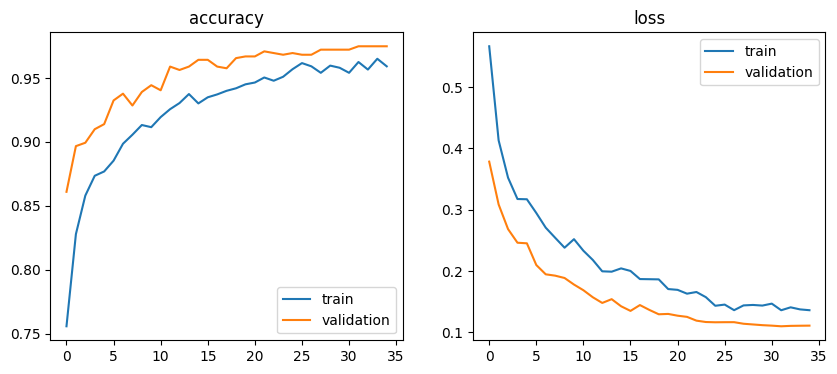

Model saved; inspect outputs/ and oral_cancer_outputs.zip


In [8]:
model.save('outputs/best_efficientnetb0.keras')
hist=pd.concat([pd.DataFrame(h1.history).assign(stage='head'),pd.DataFrame(h2.history).assign(stage='finetune')],ignore_index=True); hist.to_csv('outputs/training_history.csv',index_label='epoch')
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,k in zip(ax,['accuracy','loss']): a.plot(hist[k],label='train'); a.plot(hist['val_'+k],label='validation'); a.set_title(k); a.legend()
fig.savefig('outputs/training_history.png',dpi=160); plt.show()
# Compare the frozen-backbone checkpoint and fine-tuned model on the same validation data.
final_val=val_summary(model)
experiment=pd.DataFrame([dict(experiment_id='E0-head',architecture='EfficientNetB0',resolution='224x224',batch_size=BATCH,learning_rate=1e-3,augmentation='flip; rotation .04; zoom/contrast .08',fine_tuning='frozen backbone',duration_seconds=head_seconds,**baseline_val),dict(experiment_id='E1-finetune',architecture='EfficientNetB0',resolution='224x224',batch_size=BATCH,learning_rate=1e-5,augmentation='flip; rotation .04; zoom/contrast .08',fine_tuning='upper 40 layers; BatchNorm frozen',duration_seconds=ft_seconds,**final_val)])
experiment.to_csv('outputs/experiment_comparison.csv',index=False)
import zipfile
with zipfile.ZipFile('oral_cancer_outputs.zip','w',zipfile.ZIP_DEFLATED) as z:
 for p in Path('outputs').glob('*'): z.write(p,p.as_posix())
print('Model saved; inspect outputs/ and oral_cancer_outputs.zip')

